# Naive Bayes Baseline Model

This notebook implements a Multinomial Naive Bayes baseline classifier using TF-IDF features from cleaned CFPB consumer complaint narratives. The goal is to predict the financial product category associated with each complaint.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [2]:
data_path = Path("../../data/processed/complaint_router_modeling_data.csv")

df = pd.read_csv(data_path)

print("Dataset shape:", df.shape)
print("Number of classes:", df["Product"].nunique())
print("Missing clean narratives:", df["clean_narrative"].isna().sum())

Dataset shape: (162500, 11)
Number of classes: 11
Missing clean narratives: 6


### Prepare Modeling Data

Rows with missing or empty cleaned narratives are removed before creating the training and testing sets.

In [3]:
df = df.dropna(subset=["clean_narrative"]).copy()

df = df[
    df["clean_narrative"].str.strip() != ""
].copy()

print("Usable observations:", len(df))

Usable observations: 162494


### Train-Test Split

The dataset is divided into training and testing sets using an 80/20 stratified split. Stratification preserves the relative distribution of the 11 product categories in both sets.

In [4]:
X = df["clean_narrative"]
y = df["Product"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Number of classes:", y_train.nunique())

Training samples: 129995
Testing samples: 32499
Number of classes: 11


### TF-IDF Feature Extraction

Complaint narratives are converted into numerical features using TF-IDF. The vectorizer is fitted only on the training data to prevent information from the test set from leaking into the model.

In [5]:
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=5000,
    min_df=5
)

X_train_tfidf = vectorizer.fit_transform(X_train)
X_test_tfidf = vectorizer.transform(X_test)

print("Training TF-IDF shape:", X_train_tfidf.shape)
print("Testing TF-IDF shape:", X_test_tfidf.shape)

Training TF-IDF shape: (129995, 5000)
Testing TF-IDF shape: (32499, 5000)


### Train Multinomial Naive Bayes

A Multinomial Naive Bayes classifier is trained using the TF-IDF representation of the complaint narratives.

In [6]:
nb_model = MultinomialNB()

nb_model.fit(X_train_tfidf, y_train)

print("Naive Bayes model trained successfully.")

Naive Bayes model trained successfully.


### Model Evaluation

The trained Naive Bayes model is evaluated on the held-out test set. Performance is measured using overall accuracy and class-level precision, recall, and F1-score.

In [7]:
y_pred = nb_model.predict(X_test_tfidf)

accuracy = accuracy_score(y_test, y_pred)

print(f"Test Accuracy: {accuracy:.4f}")
print(f"Test Accuracy (%): {accuracy * 100:.2f}%")

Test Accuracy: 0.7290
Test Accuracy (%): 72.90%


In [8]:
print(classification_report(y_test, y_pred))


                                                         precision    recall  f1-score   support

                            Checking or savings account       0.57      0.86      0.68      4000
                                            Credit card       0.63      0.73      0.68      4000
    Credit reporting or other personal consumer reports       0.76      0.85      0.80      6999
                                        Debt collection       0.74      0.68      0.71      5000
                              Debt or credit management       0.79      0.25      0.38      1000
     Money transfer, virtual currency, or money service       0.90      0.53      0.67      3000
                                               Mortgage       0.87      0.88      0.87      2000
Payday loan, title loan, personal loan, or advance loan       0.72      0.45      0.56      1500
                                           Prepaid card       0.87      0.51      0.64      1000
                             

### Confusion Matrix

The confusion matrix shows which product categories are most frequently confused by the Naive Bayes classifier.

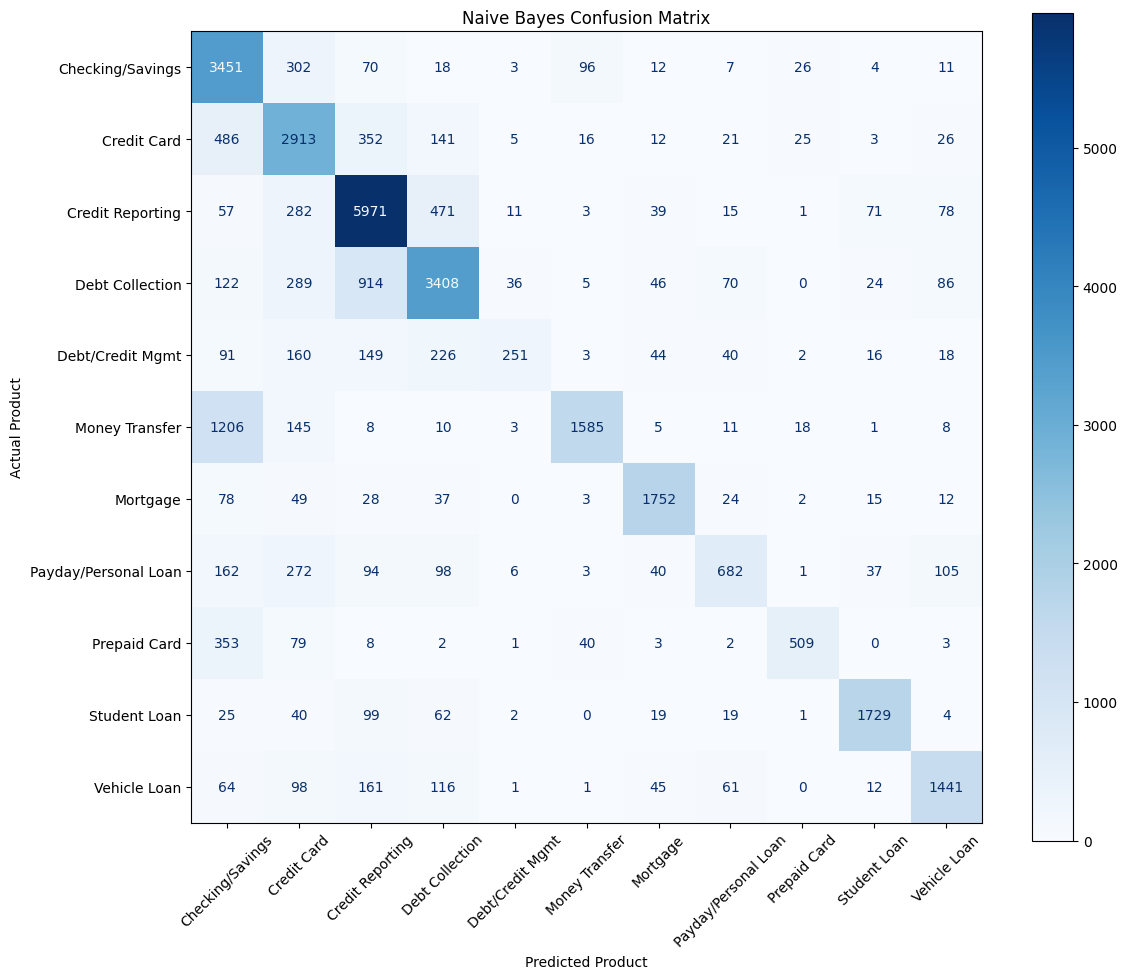

In [10]:
from sklearn.metrics import ConfusionMatrixDisplay

short_labels = {
    "Checking or savings account": "Checking/Savings",
    "Credit card": "Credit Card",
    "Credit reporting or other personal consumer reports": "Credit Reporting",
    "Debt collection": "Debt Collection",
    "Debt or credit management": "Debt/Credit Mgmt",
    "Money transfer, virtual currency, or money service": "Money Transfer",
    "Mortgage": "Mortgage",
    "Payday loan, title loan, personal loan, or advance loan": "Payday/Personal Loan",
    "Prepaid card": "Prepaid Card",
    "Student loan": "Student Loan",
    "Vehicle loan or lease": "Vehicle Loan"
}

labels = nb_model.classes_
display_labels = [short_labels[label] for label in labels]

fig, ax = plt.subplots(figsize=(12, 10))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=labels,
    display_labels=display_labels,
    xticks_rotation=45,
    cmap="Blues",
    ax=ax
)

ax.set_title("Naive Bayes Confusion Matrix")
ax.set_xlabel("Predicted Product")
ax.set_ylabel("Actual Product")

plt.tight_layout()
plt.show()

## Naive Bayes Results Summary

The Multinomial Naive Bayes classifier achieved a test accuracy of **72.90%** when classifying consumer complaint narratives across 11 product categories.

Performance varied across product categories. The model performed particularly well on categories such as **Student Loan, Mortgage, and Credit Reporting**, while categories such as **Debt or Credit Management** were more difficult to classify accurately.

The confusion matrix also shows that some categories with similar financial terminology were frequently confused. For example, many **Money Transfer** complaints were classified as **Checking or Savings Account** complaints.

Overall, the Naive Bayes model provides a solid baseline for the complaint routing system. These results can later be compared with the Logistic Regression and Linear SVM baseline models to determine which approach provides the strongest classification performance.